# Episode 4: Probability, Entropy, and Perplexity
<a href="https://colab.research.google.com/github/Kinvecta/how-llms-work/blob/main/Episode%2004%20-%20Probability%20Entropy%20and%20Perplexity/notebook.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

**Companion notebook** for the series *How Large Language Models Work: From Math to Transformers*.

The episode works every calculation by hand. This notebook does the same calculations in the same order, prints each line the way it appears on screen, and checks every value with an `assert`. It uses only `numpy` and `matplotlib` (both already in Colab): choose **Runtime, Run all**.

| Part | What you'll compute | Video numbers |
|---|---|---|
| 1 | A distribution, and the chain rule with GPT-2 small's real factors | 1.00 · 0.22 × 0.45 = 0.099 · ≈ 1.5 × 10⁻¹⁷ |
| 2 | Softmax by hand, the +5 shift, the stable form, and why the stable form matters | 0.090, 0.245, 0.665 |
| 3 | Surprisal in nats and bits, then entropy term by term for three models | 1.386 · 1.335 · 0.17 nats |
| 4 | Cross-entropy and perplexity: one token, two tokens, a whole sentence | 3.33 · ≈ 3.2 · ≈ 48 |
| 5 | The myth: confident is not correct | perplexity 100 |
| 6 | Try it yourself, with self-checks | your numbers |

Episode 1's four-word probabilities (mat 0.30, floor 0.20, sofa 0.15, other 0.35, after “The cat sat on the”) are **illustrative**. The GPT-2 small probabilities were **measured** in the Episode 1 notebook and are copied here, so this notebook needs no model download. Logs are natural (nats) unless a column says bits.

## Setup

In [1]:
import matplotlib.pyplot as plt
import numpy as np

words = ["mat", "floor", "sofa", "other"]
p = np.array([0.30, 0.20, 0.15, 0.35])        # Model A: illustrative, from Episode 1
q = np.array([0.01, 0.01, 0.97, 0.01])        # Model B: the confident model (same word order)
COLORS = ["#8FB4E8", "#C3CAD6", "#FF4D3D", "#8B98AE"]   # mat, floor, sofa, other (the video's colours)

# GPT-2 small, p(actual next token | prefix), measured in the Episode 1 notebook
gpt2 = {"cat": 0.000101484, "sat": 0.000703646, "on": 0.223966, "the": 0.453700, "mat": 0.00404395,
        "because": 0.00116167, "it": 0.217075, "was": 0.319922, "tired": 0.0226520, ".": 0.273240}

def softmax(h):
    """Stable softmax: subtract the largest score first (Goodfellow et al., Eq. 6.33)."""
    h = np.asarray(h, dtype=float)
    e = np.exp(h - h.max())
    return e / e.sum()

def entropy(dist):
    """H(p) = -sum p ln p, in nats. Terms with p = 0 contribute 0."""
    d = np.asarray(dist, dtype=float)
    d = d[d > 0]
    return float(-np.sum(d * np.log(d)))

surprisal = lambda x: -np.log(x)              # -ln p, in nats

## Part 1 · Probability and the chain rule

### Step 1: check the distribution
Every probability is between 0 and 1, and together they add to exactly 1. The video adds them one at a time.

In [2]:
running = 0.0
for w, x in zip(words, p):
    running += x
    print(f"+ {x:.2f} ({w:5s}) -> {running:.2f}")
assert np.all((p >= 0) & (p <= 1)) and np.isclose(p.sum(), 1.0)

+ 0.30 (mat  ) -> 0.30
+ 0.20 (floor) -> 0.50
+ 0.15 (sofa ) -> 0.65
+ 0.35 (other) -> 1.00


### Step 2: the chain rule with real factors
P(x₁, …, xₙ) = Π p(xₜ | x<ₜ). Each factor conditions on everything before it. The video rounds GPT-2's two factors to 0.22 and 0.45.

In [3]:
p_on, p_the = 0.22, 0.45
print(f"p(on | The cat sat) x p(the | The cat sat on) = {p_on} x {p_the} = {p_on * p_the:.3f}")
assert round(p_on * p_the, 3) == 0.099

P_sentence = np.prod(list(gpt2.values()))
print(f"all ten scored tokens: P = {P_sentence:.2e}")
assert round(P_sentence * 1e17, 1) == 1.5

# Why we switch to logs: the log of a product is the sum of the logs
log_P = np.sum(np.log(list(gpt2.values())))
print(f"ln P = sum of ln p = {log_P:.2f}   (exp of that = {np.exp(log_P):.2e})")
assert np.isclose(np.exp(log_P), P_sentence)

p(on | The cat sat) x p(the | The cat sat on) = 0.22 x 0.45 = 0.099
all ten scored tokens: P = 1.47e-17
ln P = sum of ln p = -38.76   (exp of that = 1.47e-17)


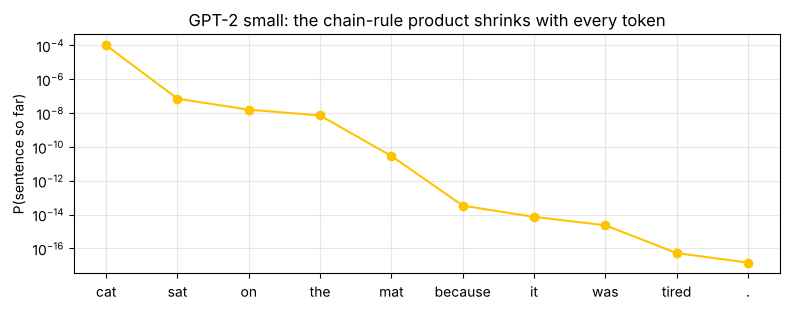

In [4]:
# How fast the product shrinks, token by token (log scale)
running = np.cumprod(list(gpt2.values()))
plt.figure(figsize=(8, 3.2))
plt.semilogy(range(1, 11), running, "o-", color="#FFC400")
plt.xticks(range(1, 11), list(gpt2.keys()))
plt.ylabel("P(sentence so far)")
plt.title("GPT-2 small: the chain-rule product shrinks with every token")
plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

## Part 2 · Softmax, by hand

softmax(h)ᵢ = exp(hᵢ) / Σⱼ exp(hⱼ): exponentiate every score, then divide by the total. `softmax_by_hand` prints the worksheet the video shows.

In [5]:
def softmax_by_hand(h, digits=3):
    h = np.asarray(h, dtype=float)
    e = np.exp(h)
    print("step 1, exponentiate:", "  ".join(f"e^{v:g} = {x:.{digits}f}" for v, x in zip(h, e)))
    total = 0.0
    for i, x in enumerate(e):
        new = total + x
        if i: print(f"step 2, add:          {total:.{digits}f} + {x:.{digits}f} = {new:.{digits}f}")
        total = new
    out = e / total
    for x, o in zip(e, out):
        print(f"step 3, divide:       {x:.{digits}f} / {total:.{digits}f} = {o:.3f}")
    print(f"check: the outputs add to {out.sum():.3f}")
    return out

s2 = softmax_by_hand([0, 1, 2])
assert np.allclose(np.round(np.exp([0, 1, 2]), 3), [1, 2.718, 7.389])
assert round(np.exp([0, 1, 2]).sum(), 3) == 11.107
assert np.allclose(np.round(s2, 3), [0.090, 0.245, 0.665])
print("each +1 in score multiplies the probability by", np.round(s2[1:] / s2[:-1], 2))

step 1, exponentiate: e^0 = 1.000  e^1 = 2.718  e^2 = 7.389
step 2, add:          1.000 + 2.718 = 3.718
step 2, add:          3.718 + 7.389 = 11.107
step 3, divide:       1.000 / 11.107 = 0.090
step 3, divide:       2.718 / 11.107 = 0.245
step 3, divide:       7.389 / 11.107 = 0.665
check: the outputs add to 1.000
each +1 in score multiplies the probability by [2.72 2.72]


### Step 3: the shift check, and how real code does it
Adding the same number to every score changes nothing: exp(s) multiplies every numerator and the denominator, and cancels. Real code uses this to subtract the largest score first.

In [6]:
print("add 5:")
s_plus5 = softmax_by_hand([5, 6, 7], digits=1)
print("\nsubtract the largest (2):")
s_minus2 = softmax_by_hand([-2, -1, 0])
assert round(np.exp([5, 6, 7]).sum(), 1) == 1648.5 and round(np.exp([-2, -1, 0]).sum(), 3) == 1.503
assert np.allclose(s_plus5, s2) and np.allclose(s_minus2, s2)

add 5:
step 1, exponentiate: e^5 = 148.4  e^6 = 403.4  e^7 = 1096.6
step 2, add:          148.4 + 403.4 = 551.8
step 2, add:          551.8 + 1096.6 = 1648.5
step 3, divide:       148.4 / 1648.5 = 0.090
step 3, divide:       403.4 / 1648.5 = 0.245
step 3, divide:       1096.6 / 1648.5 = 0.665
check: the outputs add to 1.000

subtract the largest (2):
step 1, exponentiate: e^-2 = 0.135  e^-1 = 0.368  e^0 = 1.000
step 2, add:          0.135 + 0.368 = 0.503
step 2, add:          0.503 + 1.000 = 1.503
step 3, divide:       0.135 / 1.503 = 0.090
step 3, divide:       0.368 / 1.503 = 0.245
step 3, divide:       1.000 / 1.503 = 0.665
check: the outputs add to 1.000


**Why the stable form matters.** With scores in the thousands, the naive formula overflows: e¹⁰⁰⁰ is too big for a float, so it becomes `inf`, and `inf / inf` is `nan`. Subtracting the largest score first keeps the biggest exponent at e⁰ = 1.

In [7]:
big = np.array([1000.0, 1001.0, 1002.0])
with np.errstate(over="ignore", invalid="ignore"):
    naive = np.exp(big) / np.exp(big).sum()
print("naive :", naive)
print("stable:", np.round(softmax(big), 3))
assert np.all(np.isnan(naive)) and np.allclose(softmax(big), s2)

naive : [nan nan nan]
stable: [0.09  0.245 0.665]


### Step 4: softmax returns Episode 1's distribution
Use h = ln p as the scores. They are all negative, which is fine: exp gives back p, which already sums to 1.

h = ln p = [-1.2  -1.61 -1.9  -1.05]
softmax(h) = [0.3  0.2  0.15 0.35]


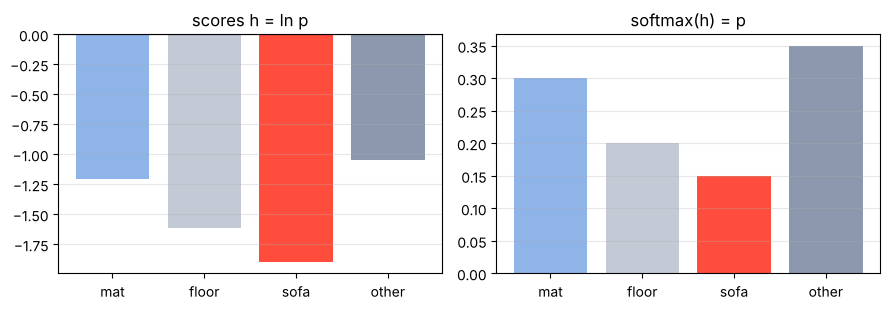

In [8]:
h = np.log(p)
print("h = ln p =", np.round(h, 2))
print("softmax(h) =", np.round(softmax(h), 2))
assert np.allclose(np.round(h, 2), [-1.20, -1.61, -1.90, -1.05])
assert np.allclose(softmax(h), p)

fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
ax[0].bar(words, h, color=COLORS); ax[0].axhline(0, color="k", lw=0.8); ax[0].set_title("scores h = ln p")
ax[1].bar(words, softmax(h), color=COLORS); ax[1].set_title("softmax(h) = p")
for a in ax: a.grid(alpha=0.3, axis="y")
plt.tight_layout(); plt.show()

## Part 3 · Surprisal and entropy

### Step 5: surprisal, in nats and bits
Surprisal = −ln p. Rare outcomes surprise more. Bits = nats ÷ ln 2 (= 0.693).

In [9]:
print(f"{'word':6s} {'p':>5s} {'nats':>6s} {'bits':>6s}")
for w, x in zip(words, p):
    print(f"{w:6s} {x:5.2f} {surprisal(x):6.2f} {surprisal(x) / np.log(2):6.2f}")
assert np.allclose(np.round(surprisal(p), 2), [1.20, 1.61, 1.90, 1.05])
assert np.allclose(np.round(surprisal(p) / np.log(2), 2), [1.74, 2.32, 2.74, 1.51])
assert surprisal(1.0) == 0

word       p   nats   bits
mat     0.30   1.20   1.74
floor   0.20   1.61   2.32
sofa    0.15   1.90   2.74
other   0.35   1.05   1.51


### Step 6: entropy, term by term
H(p) = −Σ pᵢ ln pᵢ: each surprisal weighted by how often it happens. `entropy_by_hand` prints one row per outcome, like the video's three worked examples.

In [10]:
def entropy_by_hand(dist, labels=None, name=""):
    dist = np.asarray(dist, dtype=float)
    labels = labels or [f"x{i+1}" for i in range(len(dist))]
    print(name)
    for lab, x in zip(labels, dist):
        print(f"  {lab:6s} {x:.2f} x {surprisal(x):.3f} = {x * surprisal(x):.3f}")
    H = entropy(dist)
    print(f"  H = {H:.3f} nats = {H / np.log(2):.2f} bits\n")
    return H

H_uniform = entropy_by_hand([0.25] * 4, words, "Example 1: four equal outcomes")
H_A = entropy_by_hand(p, words, "Example 2: Episode 1's model (Model A)")
H_B = entropy_by_hand(q, words, "Example 3: the confident model (Model B)")

assert round(0.25 * np.log(4), 3) == 0.347 and np.isclose(H_uniform, np.log(4)) and round(H_uniform / np.log(2), 6) == 2
assert np.allclose(np.round(p * surprisal(p), 3), [0.361, 0.322, 0.285, 0.367])
assert round(H_A, 3) == 1.335 and round(H_A / np.log(2), 2) == 1.93
assert round(0.01 * surprisal(0.01), 3) == 0.046 and round(3 * 0.01 * surprisal(0.01), 3) == 0.138
assert round(H_B, 2) == 0.17
print(f"Model A is {H_A / H_B:.1f}x as spread out as Model B")

Example 1: four equal outcomes
  mat    0.25 x 1.386 = 0.347
  floor  0.25 x 1.386 = 0.347
  sofa   0.25 x 1.386 = 0.347
  other  0.25 x 1.386 = 0.347
  H = 1.386 nats = 2.00 bits

Example 2: Episode 1's model (Model A)
  mat    0.30 x 1.204 = 0.361
  floor  0.20 x 1.609 = 0.322
  sofa   0.15 x 1.897 = 0.285
  other  0.35 x 1.050 = 0.367
  H = 1.335 nats = 1.93 bits

Example 3: the confident model (Model B)
  mat    0.01 x 4.605 = 0.046
  floor  0.01 x 4.605 = 0.046
  sofa   0.97 x 0.030 = 0.030
  other  0.01 x 4.605 = 0.046
  H = 0.168 nats = 0.24 bits

Model A is 8.0x as spread out as Model B


**Picture it.** For two outcomes, entropy is largest when they are equally likely (ln 2 nats = 1 bit) and falls to 0 as one outcome becomes certain. The right panel puts our three models side by side.

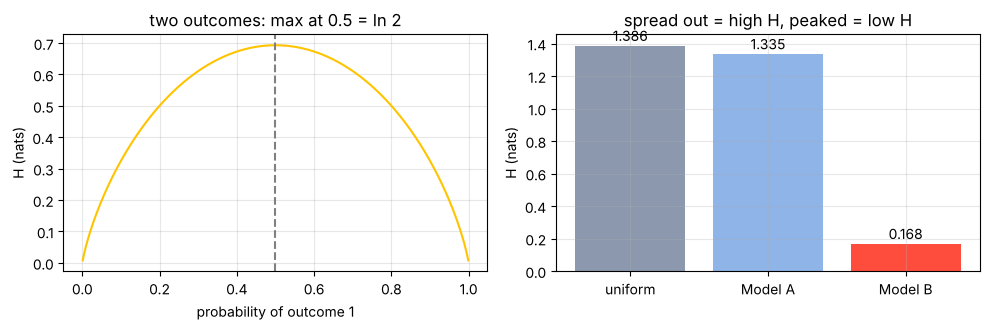

In [11]:
x = np.linspace(0.001, 0.999, 400)
H2 = -(x * np.log(x) + (1 - x) * np.log(1 - x))
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].plot(x, H2, color="#FFC400"); ax[0].axvline(0.5, ls="--", color="gray")
ax[0].set_xlabel("probability of outcome 1"); ax[0].set_ylabel("H (nats)"); ax[0].set_title("two outcomes: max at 0.5 = ln 2")
ax[1].bar(["uniform", "Model A", "Model B"], [H_uniform, H_A, H_B], color=["#8B98AE", "#8FB4E8", "#FF4D3D"])
for i, v in enumerate([H_uniform, H_A, H_B]): ax[1].text(i, v + 0.03, f"{v:.3f}", ha="center")
ax[1].set_ylabel("H (nats)"); ax[1].set_title("spread out = high H, peaked = low H")
for a in ax: a.grid(alpha=0.3)
plt.tight_layout(); plt.show()
assert np.isclose(H2.max(), np.log(2), atol=1e-4)

### Step 7: e to the entropy, and the lumped bucket
exp(H) is the number of equally likely choices with the same entropy: exactly 4 for the uniform model, 3.80 for Model A. And “other” stands for many tokens; splitting it can only raise H, so 1.335 nats is a lower bound for Model A.

In [12]:
print(f"exp(H): uniform {np.exp(H_uniform):.2f}, Model A {np.exp(H_A):.2f}")
assert np.isclose(np.exp(H_uniform), 4) and round(np.exp(H_A), 2) == 3.80

for k in (1, 2, 5, 20):
    full = H_A + 0.35 * np.log(k)          # "other" split into k equally likely tokens
    print(f"other split into {k:2d} tokens: H = {full:.3f} nats (never below {H_A:.3f})")
    assert full >= H_A - 1e-12
split = np.array([0.30, 0.20, 0.15] + [0.35 / 5] * 5)
assert np.isclose(entropy(split), H_A + 0.35 * np.log(5))
print("for scale: GPT-2 small at the same point, over all 50,257 tokens, is about 5.4 nats (Episode 1 notebook)")

exp(H): uniform 4.00, Model A 3.80
other split into  1 tokens: H = 1.335 nats (never below 1.335)
other split into  2 tokens: H = 1.578 nats (never below 1.335)
other split into  5 tokens: H = 1.898 nats (never below 1.335)
other split into 20 tokens: H = 2.384 nats (never below 1.335)
for scale: GPT-2 small at the same point, over all 50,257 tokens, is about 5.4 nats (Episode 1 notebook)


## Part 4 · Cross-entropy and perplexity

### Step 8: one observed token
If the next word is “mat”, the target puts all its weight on mat, so the cross-entropy is one term: −ln 0.30. Perplexity is e to that, which is 1/p for a single token.

In [13]:
for w, x in zip(words[:3], p[:3]):
    ce = surprisal(x)
    print(f"next word = {w:5s}: CE = {ce:.3f} nats, PP = e^{ce:.3f} = {np.exp(ce):.2f} = 1/{x:.2f}")
assert round(surprisal(0.30), 3) == 1.204 and round(np.exp(surprisal(0.30)), 2) == 3.33
assert np.isclose(1 / 0.20, 5) and round(1 / 0.15, 2) == 6.67

# Cross-entropy is entropy plus a non-negative mismatch (KL): a model can tie the target, never beat it
target = np.array([0.30, 0.20, 0.15, 0.35])
for name, model in [("matches", target), ("Model B", q)]:
    H_qp = float(-np.sum(target * np.log(model)))
    print(f"model {name:8s}: H(q,p) = {H_qp:.3f} >= H(q) = {entropy(target):.3f}")
    assert H_qp >= entropy(target) - 1e-12

next word = mat  : CE = 1.204 nats, PP = e^1.204 = 3.33 = 1/0.30
next word = floor: CE = 1.609 nats, PP = e^1.609 = 5.00 = 1/0.20
next word = sofa : CE = 1.897 nats, PP = e^1.897 = 6.67 = 1/0.15
model matches : H(q,p) = 1.335 >= H(q) = 1.335
model Model B : H(q,p) = 3.919 >= H(q) = 1.335


### Step 9: perplexity of real text (GPT-2 small)
Average the surprisals of the tokens that actually appear, then take e to that average. First the two tokens from the video (rounded), then the whole sentence.

In [14]:
s_on, s_the = surprisal(0.22), surprisal(0.45)
ce2 = (s_on + s_the) / 2
print(f"-ln 0.22 = {s_on:.2f}, -ln 0.45 = {s_the:.2f}; sum {s_on + s_the:.2f}; / 2 = {ce2:.2f} nats; PP = e^{ce2:.2f} = {np.exp(ce2):.1f}")
print(f"check: 1 / sqrt(0.099) = {1 / np.sqrt(0.099):.1f}  (one over the geometric mean)")
assert round(np.exp(ce2), 1) == 3.2 and round(1 / np.sqrt(0.099), 1) == 3.2

surp = surprisal(np.array(list(gpt2.values())))
ce = surp.mean()
print(f"whole sentence: average surprisal = {ce:.2f} nats; perplexity = {np.exp(ce):.0f}")
assert round(ce, 2) == 3.88 and round(np.exp(ce)) == 48

-ln 0.22 = 1.51, -ln 0.45 = 0.80; sum 2.31; / 2 = 1.16 nats; PP = e^1.16 = 3.2
check: 1 / sqrt(0.099) = 3.2  (one over the geometric mean)
whole sentence: average surprisal = 3.88 nats; perplexity = 48


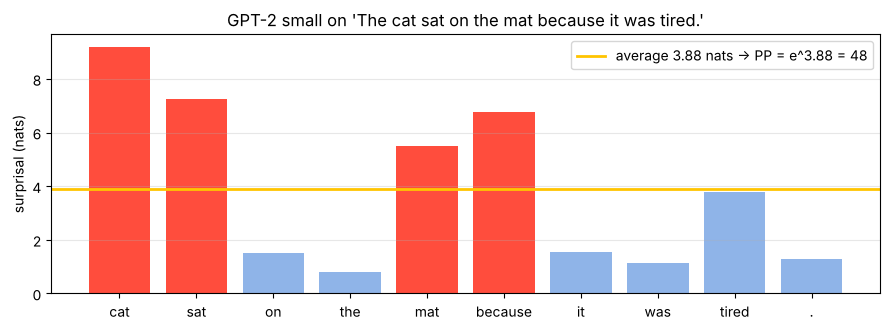

In [15]:
plt.figure(figsize=(9, 3.4))
plt.bar(list(gpt2.keys()), surp, color=["#FF4D3D" if s > 5 else "#8FB4E8" for s in surp])
plt.axhline(ce, color="#FFC400", lw=2, label=f"average {ce:.2f} nats -> PP = e^{ce:.2f} = {np.exp(ce):.0f}")
plt.ylabel("surprisal (nats)"); plt.title("GPT-2 small on 'The cat sat on the mat because it was tired.'")
plt.legend(); plt.grid(alpha=0.3, axis="y"); plt.tight_layout(); plt.show()

## Part 5 · The myth: confident is not correct
Model B has low entropy (very sure). If the next word is “mat”, which it gave 0.01, its perplexity on that token is 1/0.01 = 100. Entropy reads the shape of a distribution, not whether it is right.

In [16]:
print(f"Model B entropy = {entropy(q):.2f} nats (uniform: {np.log(4):.2f})")
print(f"next word = mat -> PP = 1/{q[0]} = {1 / q[0]:.0f}")
assert round(entropy(q), 2) == 0.17 and round(1 / q[0]) == 100

# Entropy ignores which word gets the 0.97: moving it changes nothing
assert np.isclose(entropy([0.97, 0.01, 0.01, 0.01]), entropy(q))

Model B entropy = 0.17 nats (uniform: 1.39)
next word = mat -> PP = 1/0.01 = 100


### Check question
A model spreads its probability evenly over four words. (a) Entropy in nats and bits? (b) Perplexity? (c) A second model gives “mat” 0.97 and 0.01 to each of the others. Higher or lower entropy?

In [17]:
print(f"(a) {np.log(4):.2f} nats = {np.log(4) / np.log(2):.0f} bits   (b) {np.exp(np.log(4)):.0f}   "
      f"(c) lower: {entropy([0.97, 0.01, 0.01, 0.01]):.2f} against {np.log(4):.2f}")
assert round(np.log(4), 2) == 1.39 and entropy([0.97, 0.01, 0.01, 0.01]) < np.log(4)

(a) 1.39 nats = 2 bits   (b) 4   (c) lower: 0.17 against 1.39


## Part 6 · Try it yourself
Change the values in the next cell and re-run it. The self-checks tell you whether your own hand calculation matches.

1. Pick three scores, softmax them by hand on paper, then type your answer into `my_answer`.
2. Add 10 to every score and confirm nothing changes.
3. Even out the four bars of `my_dist` and watch H climb toward ln 4 = 1.39 nats.

In [18]:
my_scores = [2.0, 0.5, -1.0]           # 1. your scores
my_answer = None                       #    e.g. [0.79, 0.18, 0.04] from your paper

out = softmax_by_hand(my_scores)
if my_answer is not None:
    ok = np.allclose(out, my_answer, atol=0.01)
    print("your answer matches" if ok else f"not quite: expected {np.round(out, 3)}")
assert np.allclose(softmax(np.array(my_scores) + 10), out)      # 2. the shift check holds for any scores

my_dist = [0.40, 0.30, 0.20, 0.10]     # 3. must add to 1
assert np.isclose(sum(my_dist), 1), "your distribution must add to 1"
print(f"\nH(my_dist) = {entropy(my_dist):.3f} nats; e^H = {np.exp(entropy(my_dist)):.2f} 'equal choices' (max {np.log(4):.2f} nats, 4 choices)")

step 1, exponentiate: e^2 = 7.389  e^0.5 = 1.649  e^-1 = 0.368
step 2, add:          7.389 + 1.649 = 9.038
step 2, add:          9.038 + 0.368 = 9.406
step 3, divide:       7.389 / 9.406 = 0.786
step 3, divide:       1.649 / 9.406 = 0.175
step 3, divide:       0.368 / 9.406 = 0.039
check: the outputs add to 1.000

H(my_dist) = 1.280 nats; e^H = 3.60 'equal choices' (max 1.39 nats, 4 choices)


In [19]:
print("All Episode 4 checks passed.")

All Episode 4 checks passed.
